# DNAffinity: MD-derived DNA shape vs. Gata4 HT-SELEX affinity

End-to-end reproduction of the **SELEX shape report** (`outputs/selex_new_shape/report/SELEX_shape_report.pdf`, branch `selex-new-shape`).

**Aim of the study:** can good protein–DNA affinity prediction be achieved from *molecular-dynamics (MD) simulation data only*? Labels are Gata4 HT-SELEX 10-mer affinities (`data/selex/Gata4/4.txt`); the only features are the new MD tables `data/selex/{tetramer,hexamer}/{avg,fce}_*.dat` (average helical parameters `avg`, stiffness matrix `fce`) and, for comparison, a one-hot encoding of the sequence.

The notebook uses the report's own code (`scripts/selex_new_shape/`: `lib.py`, `selex_pipeline.py` = importable version of `train_final.py`, `lrp.py`, `lrp_agg.py`) and the repository models in `dnaffinity/models/`. Nothing else is used as input.

| Section | Content |
|---|---|
| 1 | Load and characterise the data |
| 2 | Preprocessing step by step |
| 3 | Feature sets (a)–(g) |
| 4–7 | Train one model, curves, truth vs. prediction, metrics |
| 8 | Benchmark: models × feature sets (QUICK / FULL / precomputed report numbers) |
| 9 | LRP feature importance (DFN, CNN1D) |
| 10 | Control: shuffled MD table |
| 11 | Timing |

**Run modes.** `MODE = 'QUICK'` (default; CPU, minutes): one fold, one seed, 40 epochs (patience 10) — numbers are close to, but not identical with, the report. `MODE = 'FULL'`: 5 folds × 3 seeds, 300 epochs (patience 25), the report's protocol (hours on CPU). The cell in section 8 that loads `outputs/selex_new_shape/benchmark_featuresets.csv` always gives the exact report numbers.

In [1]:
# Google Colab: clone the repository (branch selex-new-shape) and install the few dependencies
import os, sys
if 'google.colab' in str(get_ipython()):
    if not os.path.isdir('DNAffinity'):
        !git clone -b selex-new-shape https://github.com/PieterZanders/DNAffinity.git
    os.chdir('DNAffinity')
    !git checkout selex-new-shape
    !pip install -q torch scikit-learn scipy pandas matplotlib tqdm logomaker
else:
    pass

In [2]:
# Setup: repository root, importable report code, imports
from pathlib import Path
REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / 'scripts' / 'selex_new_shape'))

import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings('ignore')

from selex_pipeline import *          # lib.py (data, features, split, metrics) + training code of the report
import lrp                            # exact LRP of the report (BatchNorm folding, eps/gamma rules)
from lrp_agg import PAR, FCE, NUC, per_base, groups, absgroups
try:
    import logomaker
except ImportError:
    logomaker = None

np.random.seed(20)
set_threads()
NB_OUT = OUT / 'notebook'; NB_OUT.mkdir(parents=True, exist_ok=True)   # outputs/ is git-ignored
print('Repo root:', REPO_ROOT)

Repo root: /workspace/DNAffinity


## 0. Settings

* `MODE`: `'QUICK'` or `'FULL'` (see above).
* `FEATURE_SET`: `'a'`..`'g'` — (a) tetramer MD + one-hot, (b) hexamer MD + one-hot, (c) tetramer+hexamer MD + one-hot, (d) one-hot only, (e) tetramer MD only, (f) hexamer MD only, (g) tetramer+hexamer MD only.
* `MODEL`: `linear`, `ridge`, `svr`, `rf`, `dfn`, `cnn1d`, `cnnattention`, `transformer`.
* `BENCH_SETS`, `BENCH_MODELS`: what the benchmark loop of section 8 runs (default QUICK: sets a, d, e = MD + one-hot, one-hot only, MD only, all 8 models; FULL: all 7 sets).

In [3]:
MODE = 'QUICK'            # 'QUICK' (minutes) or 'FULL' (report protocol)
FEATURE_SET = 'a'         # a b c d e f g
MODEL = 'cnn1d'           # linear ridge svr rf dfn cnn1d cnnattention transformer
BENCH_SETS = None         # None -> QUICK: 'ade', FULL: 'abcdefg'
BENCH_MODELS = None       # None -> all 8 models
LRP_SETS = 'ae'           # LRP on DFN and CNN1D for these tetramer sets (a, d, e are supported)
PERM_SEEDS = None         # None -> QUICK: (1,), FULL: (1, 2)

In [4]:
RUNS_CFG = {'QUICK': dict(folds=[0], seeds=[0], epochs=40, patience=10),
            'FULL':  dict(folds=[0, 1, 2, 3, 4], seeds=[0, 1, 2], epochs=300, patience=25)}   # FULL = report protocol
RC = RUNS_CFG[MODE]
BENCH_SETS = BENCH_SETS or ('ade' if MODE == 'QUICK' else 'abcdefg')
BENCH_MODELS = BENCH_MODELS or MODELS
PERM_SEEDS = PERM_SEEDS or ((1,) if MODE == 'QUICK' else (1, 2))
cfg = FEATURE_SETS[FEATURE_SET][1]
print(f'MODE={MODE}: {RC}')
print(f'feature set {FS_LABEL[FEATURE_SET]}: {cfg}; model: {NM[MODEL]}')

MODE=QUICK: {'folds': [0], 'seeds': [0], 'epochs': 40, 'patience': 10}
feature set (a) tetramer shape + one-hot: {'tf': 'log', 'mc': 10, 'mode': 'perstrand', 'props': 'avg+fce', 'std': 1, 'ks': '4', 'onehot': 1, 'shape': 1}; model: CNN1D


## 1. Load and characterise the data

`4.txt` is the output of the SELEX analysis for Gata4 (cycle 4): one row per observed 10-mer with its observed count, expected count (Markov background model), affinity and standard error. The shape tables give, for every tetramer (256) and hexamer (4096), 6 average helical parameters (`avg`: SHIFT, SLIDE, RISE, TILT, ROLL, TWIST) and a symmetric 6×6 stiffness matrix (`fce`, 21 unique values).

In [5]:
deca = pd.read_csv(REPO_ROOT / 'data/selex/Gata4/4.txt', sep='\t')
display(deca.head())
n_possible = 4 ** 10
print(f'{len(deca):,} 10-mers of {n_possible:,} possible = {len(deca) / n_possible:.1%}  (zero-truncated: only k-mers seen at least once are listed)')
print(f'count == 1: {np.mean(deca.ObservedCount == 1):.1%};  count >= 10: {np.sum(deca.ObservedCount >= 10):,}')

# Affinity = 0.172 * (observed / expected)^(1/4)
ratio = deca.Affinity / (deca.ObservedCount / deca.ExpectedCount) ** 0.25
print(f'Affinity / (obs/exp)^0.25: mean {ratio.mean():.4f}, sd {ratio.std():.1e}   -> exact formula, affinity carries no more information than obs/exp')
print(f'median SE*sqrt(n)/Affinity = {(deca.SE * np.sqrt(deca.ObservedCount) / deca.Affinity).median():.3f}  (sqrt(2) = 1.414): SE/Aff = sqrt(2/n), i.e. 141% at n=1 and 45% at n=10')

,Kmer,ObservedCount,Probability,ExpectedCount,Affinity,SE
4,ACTTCCGGTC,810,1.027618e-06,0.708658,1.000000,0.049690
30,GACTTCCGGT,487,6.356439e-07,0.438348,0.992923,0.063631
28,TTCCGGCGGA,488,7.390216e-07,0.509638,0.956704,0.061247
5,CACTTCCGGT,799,1.254281e-06,0.864967,0.948145,0.047437
73,GGATATCCGG,371,6.086667e-07,0.419744,0.937746,0.068851


126,624 10-mers of 1,048,576 possible = 12.1%  (zero-truncated: only k-mers seen at least once are listed)
count == 1: 52.5%;  count >= 10: 13,100
Affinity / (obs/exp)^0.25: mean 0.1720, sd 2.5e-16   -> exact formula, affinity carries no more information than obs/exp
median SE*sqrt(n)/Affinity = 1.414  (sqrt(2) = 1.414): SE/Aff = sqrt(2/n), i.e. 141% at n=1 and 45% at n=10


,min_count,pairs,pearson_logAff_fwd_vs_rc
0,1,17376,0.417
1,10,2329,0.412
2,30,732,0.425


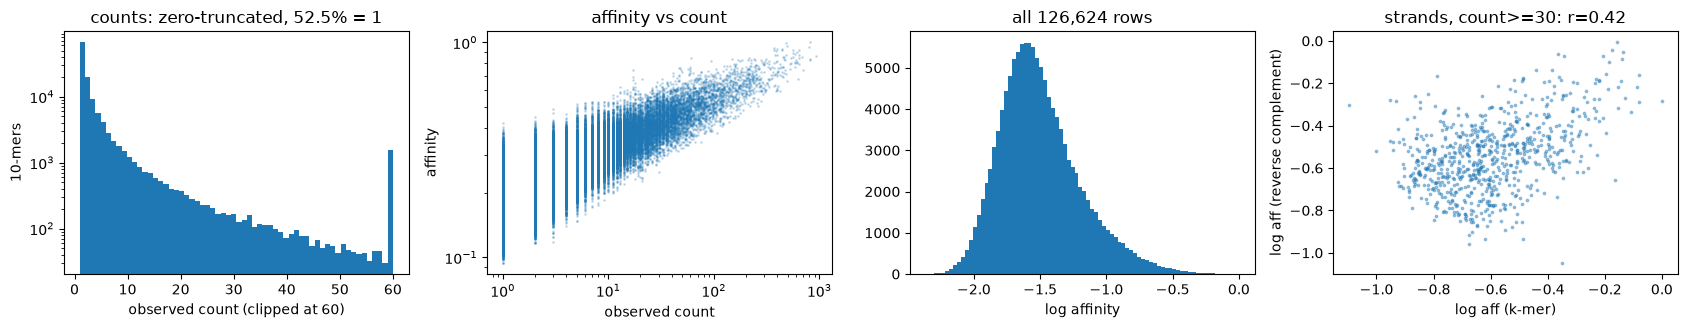

In [6]:
# strand correlation: the same 10-mer read on the two DNA strands (k-mer and its reverse complement) should have the same affinity
v = dict(zip(deca.Kmer, deca.Affinity)); n = dict(zip(deca.Kmer, deca.ObservedCount))
rows = []
for th in [1, 10, 30]:
    pr = np.array([(np.log(v[x]), np.log(v[revcomp(x)])) for x in v if x < revcomp(x) and revcomp(x) in v and n[x] >= th and n[revcomp(x)] >= th])
    rows.append(dict(min_count=th, pairs=len(pr), pearson_logAff_fwd_vs_rc=pearsonr(pr[:, 0], pr[:, 1])[0]))
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
ax[0].hist(deca.ObservedCount.clip(upper=60), bins=60); ax[0].set(xlabel='observed count (clipped at 60)', ylabel='10-mers', yscale='log', title='counts: zero-truncated, 52.5% = 1')
ax[1].scatter(deca.ObservedCount, deca.Affinity, s=1, alpha=.2); ax[1].set(xscale='log', yscale='log', xlabel='observed count', ylabel='affinity', title='affinity vs count')
ax[2].hist(np.log(deca.Affinity), bins=80); ax[2].set(xlabel='log affinity', title='all 126,624 rows')
ax[3].scatter(pr[:, 0], pr[:, 1], s=3, alpha=.4); ax[3].set(xlabel='log aff (k-mer)', ylabel='log aff (reverse complement)', title=f'strands, count>=30: r={rows[-1]["pearson_logAff_fwd_vs_rc"]:.2f}')
plt.tight_layout(); plt.show()

**Reading.** The affinity table is zero-truncated and dominated by noisy low-count entries (relative SE up to 141%). Forward and reverse-complement affinities of the same 10-mer correlate only r ≈ 0.41–0.43 at any count threshold (strand asymmetry), so the two orientations are kept as separate labelled rows ("per-strand labels"; this was +0.15–0.17 CV R² over averaging them in the report's ablation).

In [7]:
# the MD shape tables (lib.TAB[(k, 'avg'|'fce')][kmer]) used as lookup tables
for (k, q), tab in TAB.items():
    kk = next(iter(tab)); print(f'{k}-mer {q}: {len(tab):5d} entries, {len(tab[kk])} values each (e.g. {kk})')
print('avg columns:', PAR, '\nfce columns (21 unique pairs):', FCE)
tet = pd.DataFrame({k: v for k, v in TAB[(4, 'avg')].items()}, index=PAR).T
display(tet.describe().T.round(3))

4-mer avg:   256 entries, 6 values each (e.g. AAAA)
4-mer fce:   256 entries, 21 values each (e.g. AAAA)
6-mer avg:  4096 entries, 6 values each (e.g. AAAAAA)
6-mer fce:  4096 entries, 21 values each (e.g. AAAAAA)
avg columns: ['SHIFT', 'SLIDE', 'RISE', 'TILT', 'ROLL', 'TWIST'] 
fce columns (21 unique pairs): ['SHIFT-SHIFT', 'SHIFT-SLIDE', 'SHIFT-RISE', 'SHIFT-TILT', 'SHIFT-ROLL', 'SHIFT-TWIST', 'SLIDE-SLIDE', 'SLIDE-RISE', 'SLIDE-TILT', 'SLIDE-ROLL', 'SLIDE-TWIST', 'RISE-RISE', 'RISE-TILT', 'RISE-ROLL', 'RISE-TWIST', 'TILT-TILT', 'TILT-ROLL', 'TILT-TWIST', 'ROLL-ROLL', 'ROLL-TWIST', 'TWIST-TWIST']


,count,mean,std,min,25%,50%,75%,max
SHIFT,256.0,-0.000,0.335,-0.803,-0.231,-0.001,0.231,0.803
SLIDE,256.0,-0.410,0.322,-1.141,-0.670,-0.406,-0.133,0.128
RISE,256.0,3.320,0.130,2.947,3.243,3.325,3.391,3.693
TILT,256.0,-0.002,1.740,-3.748,-1.280,-0.010,1.280,3.748
ROLL,256.0,2.378,3.066,-2.732,-0.262,1.826,4.662,9.224
TWIST,256.0,33.984,2.389,28.714,32.271,34.172,35.529,40.321


## 2. Preprocessing step by step

Everything below is what `lib.py` / `selex_pipeline.py` do for every run of the report.

### 2.1 Count threshold and per-strand labels

Only 10-mers with `ObservedCount >= 10` are kept (13,100 rows). Each orientation is its own row with its own label (`mode='perstrand'`). `canonical(seq)` is the lexicographically smaller of a 10-mer and its reverse complement and defines the **group** used for leakage-free splitting.

In [8]:
d = load_labels(min_count=10, mode='perstrand')
merged = load_labels(min_count=10, mode='merged')
print(f'per-strand rows: {len(d):,} | reverse-complement groups: {d.group.nunique():,} | groups with both strands labelled: {(d.groupby("group").size() == 2).sum():,}')
print(f'(for comparison, merged mode, one averaged label per group with both orientations emitted: {len(merged):,} rows)')
display(d.head())

per-strand rows: 13,100 | reverse-complement groups: 10,771 | groups with both strands labelled: 2,329
(for comparison, merged mode, one averaged label per group with both orientations emitted: 21,522 rows)


,seq,aff,n,group
0,ACTTCCGGTC,1.000000,810,ACTTCCGGTC
1,GACTTCCGGT,0.992923,487,ACCGGAAGTC
2,TTCCGGCGGA,0.956704,488,TCCGCCGGAA
3,CACTTCCGGT,0.948145,799,ACCGGAAGTG
4,GGATATCCGG,0.937746,371,CCGGATATCC


### 2.2 Log-transformed label

Affinity is skewed (it is an obs/exp ratio to the power 1/4); the models regress `log(affinity)`.

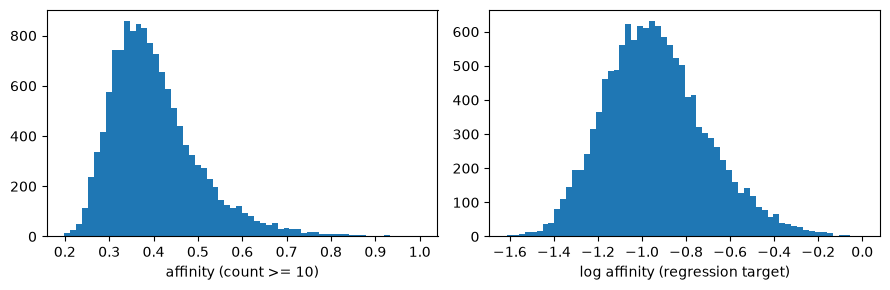

log affinity: mean -0.936, sd 0.234, range -1.61..0.00


In [9]:
y_all = tf(d.aff.values, 'log')
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); ax[0].hist(d.aff, bins=60); ax[0].set(xlabel='affinity (count >= 10)'); ax[1].hist(y_all, bins=60); ax[1].set(xlabel='log affinity (regression target)')
plt.tight_layout(); plt.show(); print(f'log affinity: mean {y_all.mean():.3f}, sd {y_all.std():.3f}, range {y_all.min():.2f}..{y_all.max():.2f}')

### 2.3 Windows and shape lookup

A 10-mer has **7 overlapping tetramer windows** `seq[i:i+4]` (i = 0..6) and **5 hexamer windows** `seq[j:j+6]` (j = 0..4). Each window is replaced by its row in the MD table: 6 `avg` + 21 `fce` = **27 numbers per window**. For per-position models the hexamer `j` is aligned to its central tetramer (position j+1; the two end positions are zero-padded).

In [10]:
seq = d.seq.iloc[0]; print('10-mer:', seq)
print('tetramer windows:', [seq[i:i + 4] for i in range(7)]); print('hexamer windows: ', [seq[j:j + 6] for j in range(5)])
cols = PAR + FCE
shape_ex = pd.DataFrame([np.concatenate([TAB[(4, 'avg')][seq[i:i + 4]], TAB[(4, 'fce')][seq[i:i + 4]]]) for i in range(7)], index=[seq[i:i + 4] for i in range(7)], columns=cols)
display(shape_ex.iloc[:, :12].round(3))
W = windowed([seq], (4,), ('avg', 'fce'), onehot=False, shape=True)[0]
print('shape-only tensor for this 10-mer:', W.shape, '  equals the lookup above:', np.allclose(W, shape_ex.values))

10-mer: ACTTCCGGTC
tetramer windows: ['ACTT', 'CTTC', 'TTCC', 'TCCG', 'CCGG', 'CGGT', 'GGTC']
hexamer windows:  ['ACTTCC', 'CTTCCG', 'TTCCGG', 'TCCGGT', 'CCGGTC']


,SHIFT,SLIDE,RISE,TILT,ROLL,TWIST,SHIFT-SHIFT,SHIFT-SLIDE,SHIFT-RISE,SHIFT-TILT,SHIFT-ROLL,SHIFT-TWIST
ACTT,0.266,-0.951,3.514,2.336,2.309,35.878,2.352,-0.468,-0.608,-0.075,-0.028,-0.073
CTTC,0.054,-0.506,3.237,2.533,0.601,33.614,1.856,-0.479,-0.474,-0.043,-0.008,-0.045
TTCC,0.177,-0.373,3.384,0.084,1.972,35.510,1.440,-0.407,-0.756,-0.096,-0.016,-0.002
TCCG,0.194,-0.288,3.419,-0.397,4.056,33.708,1.154,-0.183,-0.591,-0.129,-0.037,-0.037
CCGG,-0.063,0.088,2.947,-0.111,5.421,30.020,0.997,0.055,0.008,-0.093,-0.002,-0.000
CGGT,-0.376,-0.508,3.532,-0.800,3.798,35.892,1.510,0.559,0.356,-0.105,0.031,0.019
GGTC,-0.144,-0.832,3.377,0.487,-0.913,32.856,1.845,-0.202,-0.296,-0.056,-0.003,-0.037


shape-only tensor for this 10-mer: (7, 27)   equals the lookup above: True


### 2.4 One-hot encoding

A base is a category, not a number. Encoding A/C/G/T as 0..3 would impose an order and distances that do not exist, so each base becomes a 4-dimensional binary vector, `A=[1,0,0,0] C=[0,1,0,0] G=[0,0,1,0] T=[0,0,0,1]`. For the per-position models, the one-hot block of window i holds the 4 bases of `seq[i:i+4]` (16 values); flat models get the 10 bases once (40 values).

{'A': [1, 0, 0, 0], 'C': [0, 1, 0, 0], 'G': [0, 0, 1, 0], 'T': [0, 0, 0, 1]}
one-hot, per-position: (7, 16)  flat: (40,)
window 0 = ACTT -> [1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1]
shape + one-hot (set a): per-position (7, 43) (27 shape + 16 one-hot), flat (229,) = 7*27 + 40


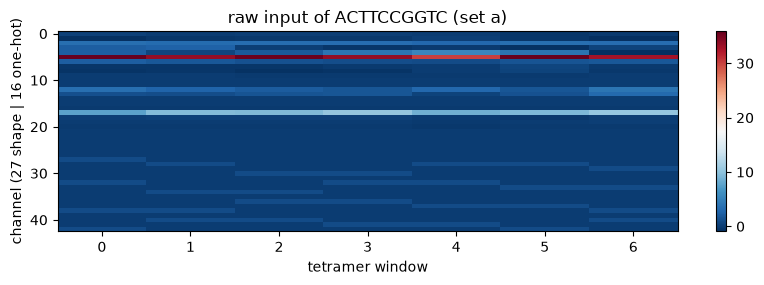

In [11]:
print({b: OH[b].astype(int).tolist() for b in 'ACGT'})
oh_w = windowed([seq], (4,), onehot=True, shape=False)[0]; oh_f = flat_feats([seq], (4,), onehot=True, shape=False)[0]
print('one-hot, per-position:', oh_w.shape, ' flat:', oh_f.shape)
print('window 0 =', seq[:4], '->', oh_w[0].astype(int))
Xw = windowed([seq], (4,), ('avg', 'fce'), onehot=True, shape=True)[0]; Xf = flat_feats([seq], (4,), ('avg', 'fce'), onehot=True, shape=True)[0]
print('shape + one-hot (set a): per-position', Xw.shape, '(27 shape + 16 one-hot), flat', Xf.shape, '= 7*27 + 40')
fig, a = plt.subplots(figsize=(10, 2.6)); im = a.imshow(Xw.T, aspect='auto', cmap='RdBu_r'); a.set(xlabel='tetramer window', ylabel='channel (27 shape | 16 one-hot)', title=f'raw input of {seq} (set a)'); plt.colorbar(im); plt.show()

### 2.5 Standardisation

Features are z-scored with the mean and sd of the **training fold only** (per channel for flat input; per channel over windows for per-position input); the target is also standardised with training-fold statistics and predictions are mapped back to log-affinity units.

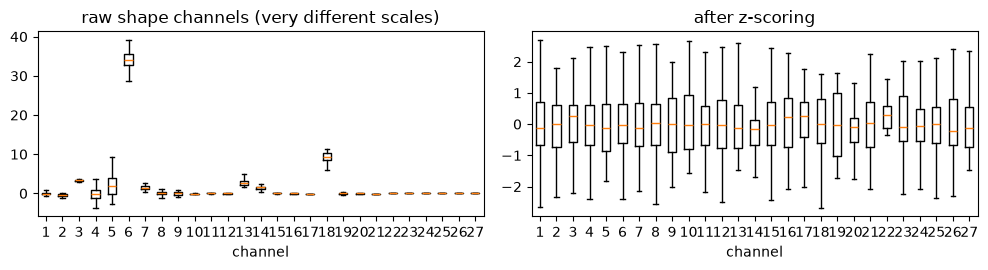

mean/sd after z-scoring (first 5 channels): [-0.     0.    -0.002  0.     0.   ] [1. 1. 1. 1. 1.]


In [12]:
X_ex = windowed(list(d.seq), (4,), ('avg', 'fce'), onehot=True, shape=True)      # (n, 7, 43)
mu, sd_ = X_ex.mean((0, 1)), X_ex.std((0, 1)) + 1e-8; Z_ex = (X_ex - mu) / sd_
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8)); ax[0].boxplot(X_ex.reshape(-1, X_ex.shape[2])[:, :27], showfliers=False); ax[0].set(title='raw shape channels (very different scales)', xlabel='channel')
ax[1].boxplot(Z_ex.reshape(-1, Z_ex.shape[2])[:, :27], showfliers=False); ax[1].set(title='after z-scoring', xlabel='channel'); plt.tight_layout(); plt.show()
print('mean/sd after z-scoring (first 5 channels):', Z_ex.mean((0, 1))[:5].round(3), Z_ex.std((0, 1))[:5].round(3))

### 2.6 Reverse-complement-grouped split

The test set is **10% of the reverse-complement groups of all k-mers of `4.txt`** (seed 20) → every k-mer and its reverse complement are either both in test or both in training. The remaining 90% (the *pool*) is split by `GroupKFold(5)`, again grouped by reverse-complement group. Neural networks additionally hold out 10% of their training fold for early stopping (`np.random.RandomState(100+fold)`).

In [13]:
d, te = labels_and_test(cfg)
pool = np.where(~te)[0]
print(f'rows: {len(d):,} | pool {len(pool):,} | held-out test {te.sum():,} ({te.mean():.1%}), {d.group[te].nunique():,} groups')
assert set(d.group[te]).isdisjoint(set(d.group[~te])), 'leak: a group is in both pool and test'
rows = []
for k, tr, va in folds(d, te):
    assert set(d.group.values[tr]).isdisjoint(set(d.group.values[va]))
    rows.append(dict(fold=k, train=len(tr), early_stop_holdout_NN=int((np.random.RandomState(100 + k).rand(len(tr)) < 0.1).sum()), validation=len(va)))
display(pd.DataFrame(rows)); print('no reverse-complement group is shared between train / validation / test: OK')

rows: 13,100 | pool 11,765 | held-out test 1,335 (10.2%), 1,084 groups


,fold,train,early_stop_holdout_NN,validation
0,0,9412,961,2353
1,1,9412,967,2353
2,2,9412,941,2353
3,3,9412,933,2353
4,4,9412,966,2353


no reverse-complement group is shared between train / validation / test: OK


## 3. Feature sets (a)–(g)

Sets (a)–(c): MD shape (tetramer, hexamer, both) **+ one-hot**; (d): **one-hot only**; (e)–(g): the same MD shape **without one-hot** (the model sees the sequence only through the MD tables). The table below is computed from the code and equals Table 1 of the report.

In [14]:
ex = list(d.seq.iloc[:3]); rows = []
for fs, (nm, c) in FEATURE_SETS.items():
    kk, pp = tuple(int(x) for x in c['ks']), tuple(c['props'].split('+'))
    xf = flat_feats(ex, kk, pp, bool(c['onehot']), bool(c['shape'])); xw = windowed(ex, kk, pp, bool(c['onehot']), bool(c['shape']))
    rows.append({'set': FS_LABEL[fs], 'flat vector (Linear, Ridge, SVR, RF, DFN)': xf.shape[1], 'per-position tensor (CNN1D, CNNAttention, Transformer)': f'7 x {xw.shape[2]}'})
display(pd.DataFrame(rows).set_index('set'))

,"flat vector (Linear, Ridge, SVR, RF, DFN)","per-position tensor (CNN1D, CNNAttention, Transformer)"
set,,
(a) tetramer shape + one-hot,229,7 x 43
(b) hexamer shape + one-hot,175,7 x 43
(c) tetra+hexa shape + one-hot,364,7 x 70
(d) one-hot only,40,7 x 16
(e) tetramer MD only,189,7 x 27
(f) hexamer MD only,135,7 x 27
(g) tetra+hexa MD only,324,7 x 54


In [15]:
# the selected feature set (FEATURE_SET) for the selected MODEL
X = features(d, MODEL, cfg); y = tf(d.aff.values, cfg['tf'])
print(f'{FS_LABEL[FEATURE_SET]}: input of {NM[MODEL]} has shape {X.shape} ({"per-position" if MODEL in WIN else "flat"}); target {y.shape}')

(a) tetramer shape + one-hot: input of CNN1D has shape (13100, 7, 43) (per-position); target (13100,)


## 4. Train a model

`MODEL` is trained with the **hyper-parameters of the report** (`selex_pipeline.nn_factory` / `sk_factory`, identical to `train_final.py`):

| Model | Settings |
|---|---|
| Linear | scikit-learn `LinearRegression` |
| Ridge | `alpha=10` |
| SVR | RBF kernel (repository default) |
| RF | 500 trees, `min_samples_leaf=3`, `max_features=0.33` |
| DFN | layers 256-128-64-1, dropout 0.2, lr 3e-4 |
| CNN1D | 64 channels, 2 residual blocks, kernel 3, average pooling, dropout 0.2, lr 1e-3 |
| CNNAttention | hidden 64, 2 blocks, kernel 3, 4 heads, 1 attention layer, dropout 0.2, lr 1e-3 |
| Transformer | d_model 32, 2 layers, 4 heads, FF 64, sinusoidal positions, mean pooling, dropout 0.2, lr 3e-4, 5 warm-up epochs |
| all NNs | AdamW weight decay 1e-2, batch 64, early stopping (report: max 300 epochs, patience 25; QUICK: 40 / 10) |

A *run* is one fold × one seed. Non-NN models are deterministic and run once per fold; NNs run 3 seeds per fold in FULL mode.

In [16]:
t0 = time.perf_counter()
runs = run_cv(MODEL, cfg, RC['folds'], RC['seeds'], RC['epochs'], RC['patience'], data=(d, te))
print(f'{NM[MODEL]} on {FS_LABEL[FEATURE_SET]}: {len(runs)} run(s) in {time.perf_counter() - t0:.1f} s')
for r in runs: print(f"  fold {r['fold']} seed {r['seed']}: fit {r['t_fit']:.1f} s, best epoch {r['best']}")

CNN1D on (a) tetramer shape + one-hot: 1 run(s) in 22.7 s
  fold 0 seed 0: fit 22.4 s, best epoch 24


## 5. Training curves

Training and early-stopping validation MSE (standardised units) per epoch; the best-validation epoch is restored. Not defined for Linear/Ridge/SVR/RF.

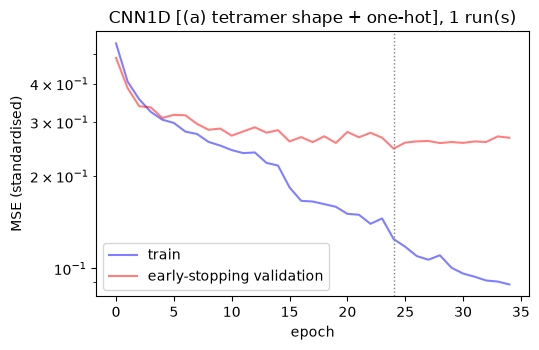

In [17]:
if runs[0]['hist'] is None:
    print(f'{NM[MODEL]} is not trained by epochs: no learning curve. Set MODEL to dfn, cnn1d, cnnattention or transformer.')
else:
    fig, a = plt.subplots(figsize=(5.5, 3.6))
    for r in runs:
        a.plot(r['hist']['train'], 'b', alpha=.5, label='train' if r is runs[0] else None); a.plot(r['hist']['val'], 'r', alpha=.5, label='early-stopping validation' if r is runs[0] else None)
        a.axvline(r['best'], c='gray', ls=':', lw=1)
    a.set(xlabel='epoch', ylabel='MSE (standardised)', yscale='log', title=f'{NM[MODEL]} [{FS_LABEL[FEATURE_SET]}], {len(runs)} run(s)'); a.legend(); plt.tight_layout(); plt.show()

## 6. Ground truth vs. prediction

Left: training rows of the fold (predictions of the fitted model); right: the held-out test set. The dashed line is y = x.

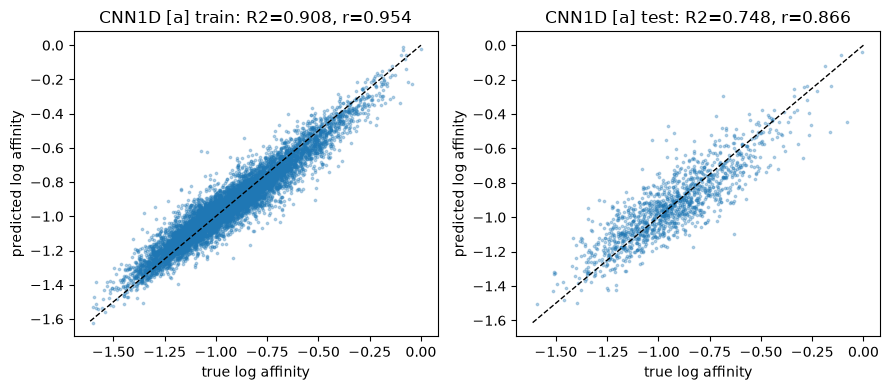

In [18]:
r = runs[0]; fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, idx, lab in [(ax[0], r['tr'], 'train'), (ax[1], r['te'], 'test')]:
    a.scatter(r['y'][idx], r['pred'][idx], s=3, alpha=.3); lo, hi = r['y'].min(), r['y'].max(); a.plot([lo, hi], [lo, hi], 'k--', lw=1)
    m_ = metrics(r['y'][idx], r['pred'][idx]); a.set(title=f"{NM[MODEL]} [{FEATURE_SET}] {lab}: R2={m_['r2']:.3f}, r={m_['pearson']:.3f}", xlabel='true log affinity', ylabel='predicted log affinity')
plt.tight_layout(); plt.show()

## 7. Metrics

R², Pearson and Spearman on log affinity (train / validation fold / held-out test), gap = train R² − test R², and *avg-runs R²* = test R² of the mean prediction over all runs. The report's numbers for the same model and feature set are shown below the table (5 folds, ×3 seeds for NNs).

In [19]:
M = pd.DataFrame([run_metrics(r) for r in runs]).set_index(['fold', 'seed']); display(M.round(3))
S = summarize(runs); rep = pd.read_csv(OUT / 'benchmark_featuresets.csv'); rr = rep[(rep.fs == FEATURE_SETS[FEATURE_SET][0]) & (rep.model == MODEL)].iloc[0]
out = pd.DataFrame({'this notebook (' + MODE + ')': [S['runs'], S['train_r2'], S['val_r2'], S['test_r2'], S['pearson'], S['spearman'], S['gap'], S['avg_runs_r2']],
                    'report (mean over its runs)': [rr.runs, rr.train_r2, rr.val_r2, rr.test_r2, rr.pearson, rr.spearman, rr.gap, rr.avg_runs_r2],
                    'report sd': [np.nan, rr.train_r2_sd, rr.val_r2_sd, rr.test_r2_sd, rr.pearson_sd, rr.spearman_sd, rr.gap_sd, np.nan]},
                   index=['runs', 'train R2', 'val R2', 'test R2', 'test Pearson', 'test Spearman', 'gap (train-test)', 'avg-runs test R2'])
display(out.round(3))

,,train_r2,val_r2,test_r2,pearson,spearman,gap,t_fit,t_inf1k
fold,seed,,,,,,,,
0,0,0.908,0.717,0.748,0.866,0.85,0.16,22.448,0.002


,this notebook (QUICK),report (mean over its runs),report sd
runs,1.000,15.000,NaN
train R2,0.908,0.889,0.032
val R2,0.717,0.735,0.015
test R2,0.748,0.736,0.012
test Pearson,0.866,0.860,0.006
test Spearman,0.850,0.844,0.007
gap (train-test),0.160,0.153,0.022
avg-runs test R2,0.748,0.788,NaN


## 8. Benchmark: all models × feature sets

### 8.1 Precomputed report numbers (exact)

`outputs/selex_new_shape/benchmark_featuresets.csv` holds the final numbers of the report (5 folds; ×3 seeds for the NNs): Tables 3–9, 11 and 12. Test R² (mean over runs) with vs. without one-hot side by side — (a) vs (e), (b) vs (f), (c) vs (g) — and one-hot only (d).

Report: test R2 (mean over runs)


fs,(a) tetramer,(e) tetramer-MD,(b) hexamer,(f) hexamer-MD,(c) tetra+hexa,(g) tetra+hexa-MD,(d) one-hot
model,,,,,,,
Linear,0.471000,0.416000,0.430000,0.314000,0.484000,0.443000,0.380000
Ridge,0.470000,0.415000,0.431000,0.314000,0.483000,0.441000,0.380000
SVR,0.598000,0.547000,0.586000,0.462000,0.588000,0.536000,0.581000
RF,0.572000,0.562000,0.549000,0.521000,0.563000,0.553000,0.536000
DFN,0.644000,0.606000,0.633000,0.529000,0.641000,0.601000,0.635000
CNN1D,0.736000,0.700000,0.714000,0.553000,0.723000,0.672000,0.739000
CNNAttention,0.725000,0.683000,0.702000,0.553000,0.709000,0.664000,0.729000
Transformer,0.685000,0.649000,0.673000,0.563000,0.681000,0.644000,0.679000


Report: averaged-runs test R2


fs,(a) tetramer,(e) tetramer-MD,(b) hexamer,(f) hexamer-MD,(c) tetra+hexa,(g) tetra+hexa-MD,(d) one-hot
model,,,,,,,
Linear,0.473000,0.418000,0.431000,0.316000,0.487000,0.446000,0.380000
Ridge,0.472000,0.417000,0.432000,0.315000,0.486000,0.444000,0.380000
SVR,0.606000,0.555000,0.594000,0.469000,0.596000,0.544000,0.590000
RF,0.581000,0.571000,0.558000,0.532000,0.572000,0.563000,0.541000
DFN,0.673000,0.638000,0.663000,0.565000,0.670000,0.633000,0.663000
CNN1D,0.788000,0.751000,0.765000,0.619000,0.773000,0.729000,0.789000
CNNAttention,0.778000,0.742000,0.758000,0.613000,0.763000,0.725000,0.785000
Transformer,0.709000,0.675000,0.699000,0.590000,0.707000,0.671000,0.702000


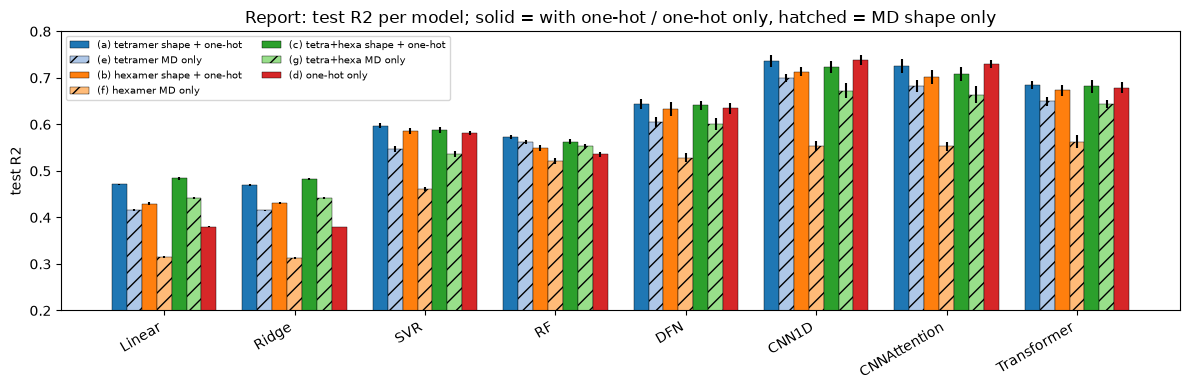

In [20]:
REPORT = pd.read_csv(OUT / 'benchmark_featuresets.csv'); FSN = {fs: FEATURE_SETS[fs][0] for fs in FEATURE_SETS}
def pivot(df, col, order='aebfcgd'):
    p = df[df.fs.isin([FSN[k] for k in order])].pivot(index='model', columns='fs', values=col)
    return p.reindex(index=MODELS, columns=[FSN[k] for k in order if FSN[k] in p.columns]).rename(index=NM, columns={FSN[k]: f'({k}) {FSN[k]}' for k in order})
print('Report: test R2 (mean over runs)'); display(pivot(REPORT, 'test_r2').round(3).style.highlight_max(axis=1, color='#cfe8cf'))
print('Report: averaged-runs test R2'); display(pivot(REPORT, 'avg_runs_r2').round(3).style.highlight_max(axis=1, color='#cfe8cf'))
def grouped_bar(df, title):
    fig, a = plt.subplots(figsize=(12, 4)); order = [k for k in 'aebfcgd' if FSN[k] in set(df.fs)]; w = .8 / len(order); col = dict(zip('abcdefg', ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#aec7e8', '#ffbb78', '#98df8a']))
    for i, k in enumerate(order):
        s_ = df[df.fs == FSN[k]].set_index('model').reindex(MODELS); a.bar(np.arange(len(MODELS)) + (i - len(order) / 2 + .5) * w, s_.test_r2, w, yerr=s_.test_r2_sd.fillna(0), color=col[k], hatch='//' if k in 'efg' else None, edgecolor='k', lw=.3, label=FS_LABEL[k])
    a.set_xticks(range(len(MODELS))); a.set_xticklabels([NM[m] for m in MODELS], rotation=30, ha='right'); a.set(ylabel='test R2', ylim=(0.2, 0.8), title=title); a.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
grouped_bar(REPORT, 'Report: test R2 per model; solid = with one-hot / one-hot only, hatched = MD shape only')

### 8.2 Run the benchmark here

Loops over `BENCH_SETS` × `BENCH_MODELS` with the QUICK or FULL protocol of `MODE`. Results are saved to `outputs/selex_new_shape/notebook/benchmark_<MODE>.csv` (git-ignored). QUICK default (sets a, d, e × 8 models) takes several minutes on a CPU; set `BENCH_SETS = 'abcdefg'` for all seven sets.

In [21]:
BENCH = []; t_bench = time.perf_counter()
for fs in BENCH_SETS:
    c_ = FEATURE_SETS[fs][1]; data_ = labels_and_test(c_)
    for m in BENCH_MODELS:
        t0 = time.perf_counter(); rs = run_cv(m, c_, RC['folds'], RC['seeds'], RC['epochs'], RC['patience'], data=data_)
        S_ = summarize(rs); S_.update(fs=FEATURE_SETS[fs][0], model=m, set=fs); BENCH.append(S_)
        print(f'({fs}) {NM[m]:13s} test R2 {S_["test_r2"]:.3f}  train {S_["train_r2"]:.3f}  avg-runs {S_["avg_runs_r2"]:.3f}  [{time.perf_counter() - t0:5.1f} s]', flush=True)
BENCH = pd.DataFrame(BENCH); BENCH.to_csv(NB_OUT / f'benchmark_{MODE}.csv', index=False)
print(f'benchmark finished in {(time.perf_counter() - t_bench) / 60:.1f} min')

(a) Linear        test R2 0.469  train 0.505  avg-runs 0.469  [  0.2 s]


(a) Ridge         test R2 0.468  train 0.503  avg-runs 0.468  [  0.2 s]


(a) SVR           test R2 0.607  train 0.747  avg-runs 0.607  [ 19.9 s]


(a) RF            test R2 0.576  train 0.885  avg-runs 0.576  [  9.2 s]


(a) DFN           test R2 0.643  train 0.801  avg-runs 0.643  [  7.9 s]


...

(e) DFN           test R2 0.613  train 0.778  avg-runs 0.613  [  7.7 s]


(e) CNN1D         test R2 0.707  train 0.838  avg-runs 0.707  [ 14.7 s]


(e) CNNAttention  test R2 0.686  train 0.820  avg-runs 0.686  [ 19.2 s]


(e) Transformer   test R2 0.581  train 0.639  avg-runs 0.581  [ 29.5 s]


benchmark finished in 5.2 min


This notebook (QUICK): test R2


fs,(a) tetramer,(e) tetramer-MD,(d) one-hot
model,,,
Linear,0.469000,0.416000,0.380000
Ridge,0.468000,0.415000,0.380000
SVR,0.607000,0.559000,0.588000
RF,0.576000,0.566000,0.541000
DFN,0.643000,0.613000,0.644000
CNN1D,0.753000,0.707000,0.736000
CNNAttention,0.743000,0.686000,0.746000
Transformer,0.636000,0.581000,0.636000


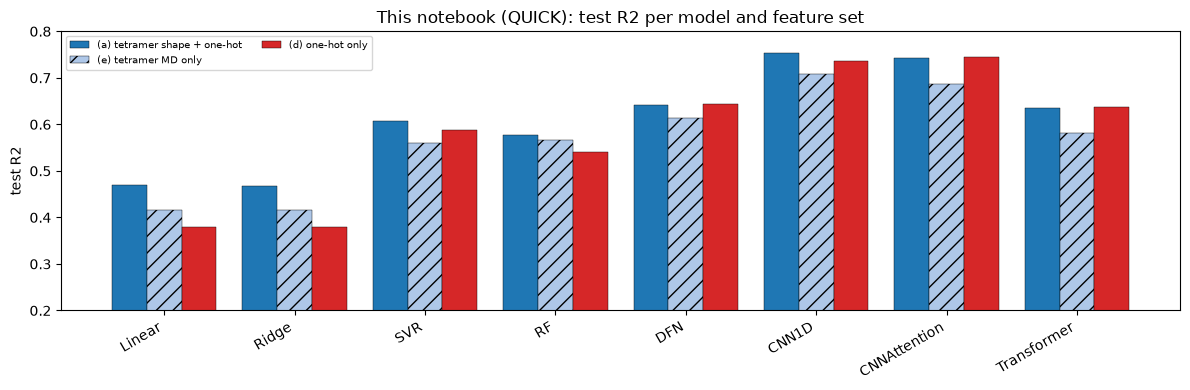

test R2 difference (notebook - report mean):


set_,a,d,e
model,,,
Linear,-0.002,-0.000,-0.000
Ridge,-0.001,-0.000,-0.000
SVR,0.010,0.007,0.012
RF,0.004,0.005,0.004
DFN,-0.001,0.009,0.007
CNN1D,0.017,-0.003,0.008
CNNAttention,0.017,0.017,0.003
Transformer,-0.049,-0.043,-0.068


mean |diff| = 0.012, max |diff| = 0.068; rank correlation of models within a set (Spearman, mean over sets): 0.97


In [22]:
print(f'This notebook ({MODE}): test R2'); display(pivot(BENCH, 'test_r2', order=''.join(k for k in 'aebfcgd' if k in BENCH_SETS)).round(3).style.highlight_max(axis=1, color='#cfe8cf'))
grouped_bar(BENCH, f'This notebook ({MODE}): test R2 per model and feature set')
# how close to the report?
cmp_ = BENCH.merge(REPORT[['fs', 'model', 'test_r2', 'test_r2_sd', 'avg_runs_r2']], on=['fs', 'model'], suffixes=('', '_report'))
cmp_['diff'] = cmp_.test_r2 - cmp_.test_r2_report
cmp_['z'] = cmp_['diff'] / cmp_.test_r2_sd_report.replace(0, np.nan)
D_ = cmp_.assign(set_=cmp_.set).pivot(index='model', columns='set_', values='diff').reindex(MODELS).rename(index=NM)
print('test R2 difference (notebook - report mean):'); display(D_.round(3))
print(f'mean |diff| = {cmp_["diff"].abs().mean():.3f}, max |diff| = {cmp_["diff"].abs().max():.3f}; rank correlation of models within a set (Spearman, mean over sets): '
      f'{np.mean([pearsonr(cmp_[cmp_.set == s].test_r2.rank(), cmp_[cmp_.set == s].test_r2_report.rank())[0] for s in BENCH_SETS]):.2f}')

**How to read the comparison.** In QUICK mode a model is trained on fold 0 with one seed and ≤40 epochs, while the report averages 5 folds × 3 seeds (300 epochs, early stopping). Differences therefore combine fold-to-fold variation (the report's sd over runs is 0.005–0.016 for the NNs), seed noise and the shorter training of the neural networks; the non-NN models are deterministic, so for them only the fold differs. The ranking of the models and the with/without one-hot pattern should be the same as in the report; `FULL` mode reproduces the report numbers.

## 9. LRP: which inputs drive the predictions?

Layer-wise Relevance Propagation (`scripts/selex_new_shape/lrp.py`, exact implementation for the repository's DFN and CNN1D): BatchNorm is folded into the preceding convolution (checked to reproduce the predictions), dropout = identity, ReLU passes relevance, the input convolution and linear layers use LRP-ε (ε = 0.01), hidden convolutions LRP-γ (γ = 0.25), residual addition and global average pooling split proportionally. The same rules with ε→0, γ=0 equal gradient × input, which is used as a sanity check. Relevance is computed on the held-out test rows (standardised log-affinity units) and averaged over the trained runs (QUICK: 1 run; FULL: 15).

Aggregation (as in the report): by **feature type** (one-hot, each `avg` parameter, `fce` diagonal, `fce` off-diagonal), per **tetramer window / base position**, and base × position maps and logos for the top-affinity k-mers. For the **MD-only set (e)** there is no per-base input, so the base-level map is *projected*: the summed relevance of each window is split equally over its 4 bases and put on the channel of the base that is present.

In [23]:
LRP = {}
for fs in LRP_SETS:
    assert fs in 'ade', 'LRP aggregation is implemented for the tetramer sets a, d, e'
    c_ = FEATURE_SETS[fs][1]; data_ = labels_and_test(c_)
    for m in ['dfn', 'cnn1d']:
        t0 = time.perf_counter(); rs = run_cv(m, c_, RC['folds'], RC['seeds'], RC['epochs'], RC['patience'], data=data_)
        LRP[(fs, m)] = dict(L=[lrp_for_run(m, r, c_) for r in rs], runs=rs, cfg=c_, test_r2=np.mean([run_metrics(r)['test_r2'] for r in rs]))
        print(f'({fs}) {NM[m]}: {len(rs)} run(s), test R2 {LRP[(fs, m)]["test_r2"]:.3f}, trained + LRP in {time.perf_counter() - t0:.1f} s')

(a) DFN: 1 run(s), test R2 0.643, trained + LRP in 7.5 s


(a) CNN1D: 1 run(s), test R2 0.753, trained + LRP in 18.1 s


(e) DFN: 1 run(s), test R2 0.613, trained + LRP in 7.4 s


(e) CNN1D: 1 run(s), test R2 0.707, trained + LRP in 21.7 s


In [24]:
def lrp_analysis(key):
    fs, m = key; L = LRP[key]['L']; kind = 'dfn' if m == 'dfn' else 'cnn'; c_ = LRP[key]['cfg']; shape, oh = bool(c_['shape']), bool(c_['onehot'])
    Rall, out, G, R0 = (np.array([l[k] for l in L]) for k in ('R', 'out', 'G', 'R0')); nr = len(L); seqs, y = L[0]['seqs'], L[0]['y']
    sr = Rall.reshape(nr, Rall.shape[1], -1).sum(2); big = np.abs(out) > 0.5
    cons = dict(runs=nr, corr=np.mean([np.corrcoef(sr[r], out[r])[0, 1] for r in range(nr)]), slope=np.mean([np.polyfit(out[r], sr[r], 1)[0] for r in range(nr)]), ratio=np.median((sr / out)[big]),
                lrp0_vs_gxi=max(np.abs(R0[r] - G[r]).max() / np.abs(G[r]).max() for r in range(nr)), corr_lrp_gxi=np.mean([np.corrcoef(Rall[r].ravel(), G[r].ravel())[0, 1] for r in range(nr)]))
    R = Rall.mean(0); gs, _, ws = groups(R, kind, shape, oh); ga, _, wsa = absgroups(R, kind, shape, oh); tot = sum(v.mean() for v in ga.values()); top100 = np.argsort(-y)[:100]
    G_ = pd.DataFrame([dict(group=k, abs_share=ga[k].mean() / tot, signed_mean=gs[k].mean(), signed_top100=gs[k][top100].mean()) for k in gs]).set_index('group')
    return dict(cons=cons, groups=G_, R=R, seqs=seqs, y=y, kind=kind, shape=shape, oh=oh, win_abs=None if wsa is None else wsa.mean(0))
AN = {k: lrp_analysis(k) for k in LRP}
cons = pd.DataFrame({f'{NM[m]} ({fs})': a['cons'] for (fs, m), a in AN.items()}).T; print('Sanity checks (corr/slope/ratio: sum_j R_j vs f(x); LRP-0 vs gradient x input):'); display(cons.round(4))

Sanity checks (corr/slope/ratio: sum_j R_j vs f(x); LRP-0 vs gradient x input):


,runs,corr,slope,ratio,lrp0_vs_gxi,corr_lrp_gxi
DFN (a),1.0,0.9909,0.7924,0.7616,0.0,0.9853
CNN1D (a),1.0,0.5655,0.5129,0.4468,0.0,0.1411
DFN (e),1.0,0.9927,0.8112,0.8038,0.0,0.9840
CNN1D (e),1.0,0.6455,0.5063,0.5132,0.0,0.2332


**Sanity checks.** For the DFN the relevance sum tracks the output (corr ≈ 0.98) and LRP-0 equals gradient × input to numerical precision. For CNN1D only about half of the output is recovered (BatchNorm biases absorb part of the relevance), and the composite γ rule differs from gradient × input — a caveat of the CNN maps, as discussed in the report.

Share of total |R| per feature type:


,DFN (a),CNN1D (a),DFN (e),CNN1D (e)
group,,,,
one-hot,0.312,0.447,NaN,NaN
avg SHIFT,0.019,0.022,0.028,0.043
avg SLIDE,0.024,0.023,0.030,0.041
avg RISE,0.020,0.019,0.030,0.038
avg TILT,0.019,0.022,0.037,0.048
avg ROLL,0.018,0.018,0.029,0.039
avg TWIST,0.020,0.022,0.032,0.036
fce diagonal,0.143,0.116,0.189,0.193
fce off-diagonal,0.425,0.309,0.626,0.560


Mean signed relevance on the top-100 test k-mers:


,DFN (a),CNN1D (a),DFN (e),CNN1D (e)
group,,,,
one-hot,0.380,0.678,NaN,NaN
avg SHIFT,-0.018,0.030,-0.059,-0.004
avg SLIDE,0.026,0.018,0.055,0.012
avg RISE,0.138,0.061,0.209,0.158
avg TILT,-0.017,0.005,-0.038,-0.007
avg ROLL,-0.013,0.011,-0.031,0.021
avg TWIST,0.022,0.015,0.027,0.033
fce diagonal,0.115,0.090,0.129,0.147
fce off-diagonal,0.480,0.351,0.670,0.565


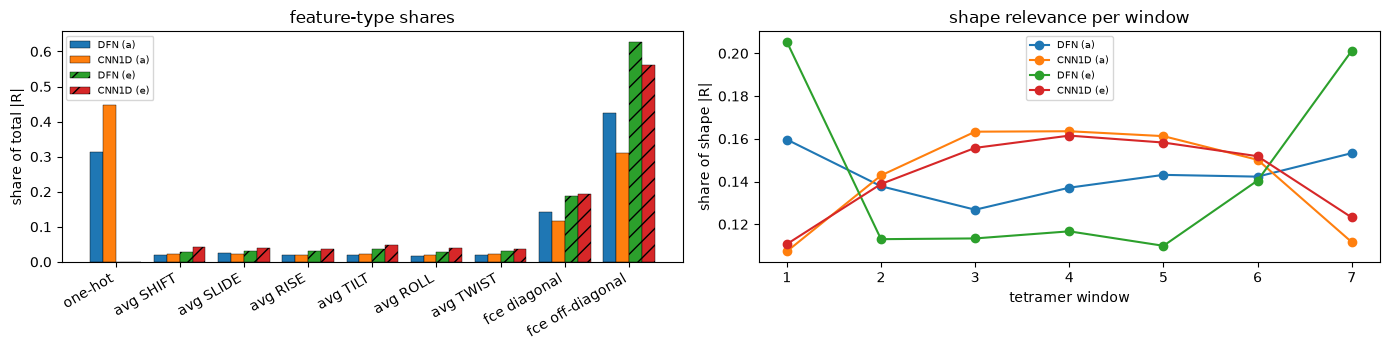

In [25]:
shares = pd.concat({f'{NM[m]} ({fs})': a['groups'].abs_share for (fs, m), a in AN.items()}, axis=1); print('Share of total |R| per feature type:'); display(shares.round(3))
print('Mean signed relevance on the top-100 test k-mers:'); display(pd.concat({f'{NM[m]} ({fs})': a['groups'].signed_top100 for (fs, m), a in AN.items()}, axis=1).round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6)); gs_ = list(shares.index); w = .8 / len(AN)
for i, c in enumerate(shares.columns): ax[0].bar(np.arange(len(gs_)) + (i - len(AN) / 2 + .5) * w, shares[c].fillna(0), w, label=c, edgecolor='k', lw=.3, hatch='//' if '(e)' in c else None)
ax[0].set_xticks(range(len(gs_))); ax[0].set_xticklabels(gs_, rotation=30, ha='right'); ax[0].set(ylabel='share of total |R|', title='feature-type shares'); ax[0].legend(fontsize=7)
for (fs, m), a in AN.items():
    if a['win_abs'] is not None: ax[1].plot(range(1, 8), a['win_abs'] / a['win_abs'].sum(), 'o-', label=f'{NM[m]} ({fs})')
ax[1].set(xlabel='tetramer window', ylabel='share of shape |R|', title='shape relevance per window'); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

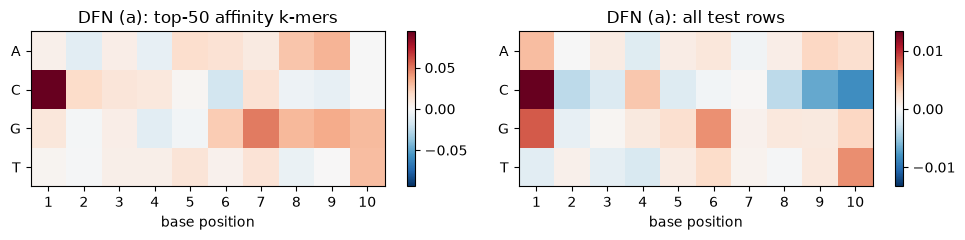

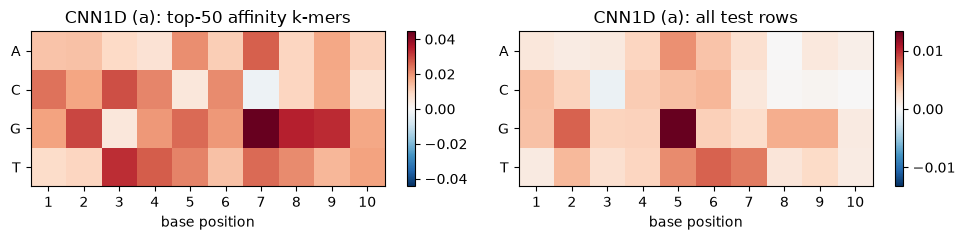

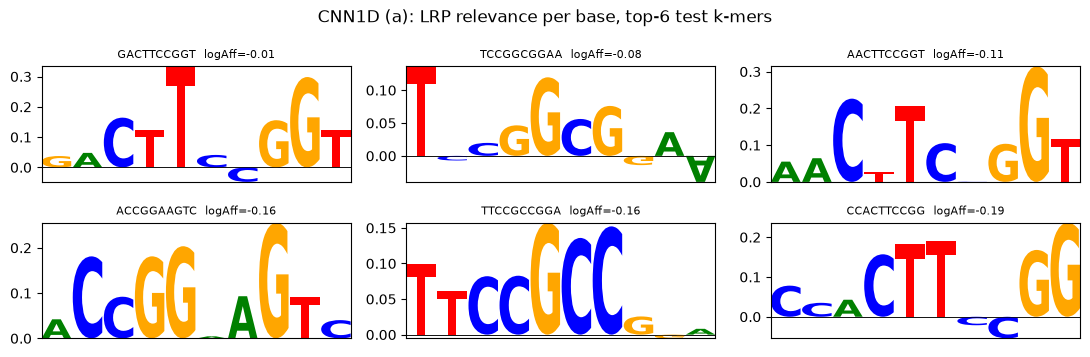

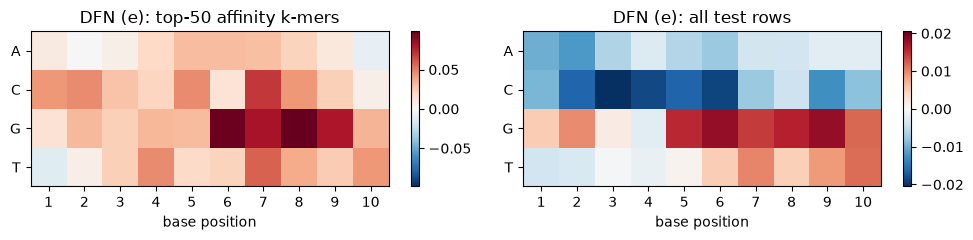

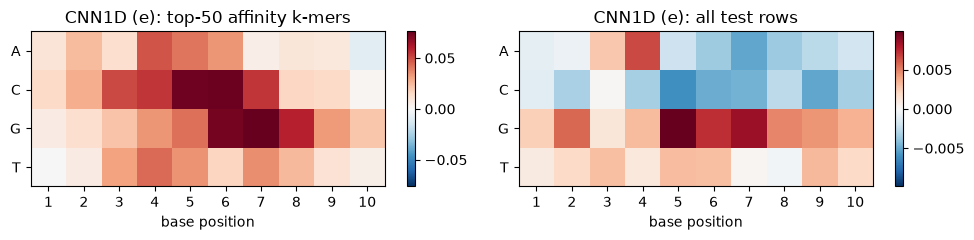

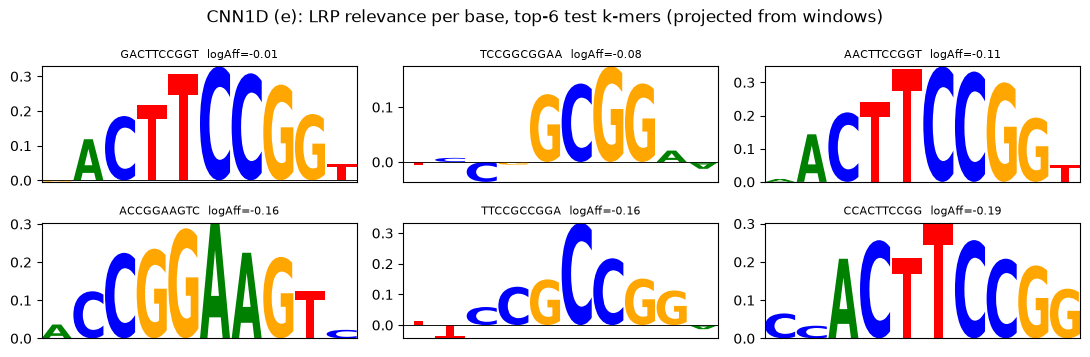

In [26]:
# base x position maps (top-50 affinity k-mers / all test rows) and logos of the top-6 k-mers (letter height = relevance of the position)
for (fs, m), a in AN.items():
    B = per_base(a['R'], a['kind'], a['shape'], a['oh'], a['seqs']); top = np.argsort(-a['y'])[:50]
    fig, ax = plt.subplots(1, 2, figsize=(10, 2.5))
    for axx, idx, t in [(ax[0], top, 'top-50 affinity k-mers'), (ax[1], slice(None), 'all test rows')]:
        H = B[idx].mean(0).T; v = np.abs(H).max(); im = axx.imshow(H, cmap='RdBu_r', vmin=-v, vmax=v, aspect='auto'); axx.set_yticks(range(4)); axx.set_yticklabels(list(NUC)); axx.set_xticks(range(10)); axx.set_xticklabels(range(1, 11)); axx.set(xlabel='base position', title=f'{NM[m]} ({fs}): {t}'); plt.colorbar(im, ax=axx)
    plt.tight_layout(); plt.show()
    if logomaker is not None and m == 'cnn1d':
        Btot = B.sum(2); fig, ax = plt.subplots(2, 3, figsize=(11, 3.6))
        for axx, i in zip(ax.ravel(), top[:6]):
            M_ = pd.DataFrame(0.0, index=range(10), columns=list(NUC))
            for j, ch in enumerate(a['seqs'][i]): M_.loc[j, ch] = Btot[i, j]
            logomaker.Logo(M_, ax=axx, color_scheme='classic'); axx.axhline(0, c='k', lw=.5); axx.set_title(f"{a['seqs'][i]}  logAff={a['y'][i]:.2f}", fontsize=8); axx.set_xticks([])
        fig.suptitle(f'{NM[m]} ({fs}): LRP relevance per base, top-6 test k-mers' + (' (projected from windows)' if not a['oh'] else '')); plt.tight_layout(); plt.show()

In [27]:
# largest fce terms and comparison with the report's LRP table (all folds x seeds)
for (fs, m), a in AN.items():
    if not a['shape']: continue
    R = a['R']; n_ = len(R)
    Fr = np.abs(R[:, :, 6:27]).sum(1).mean(0) if a['kind'] == 'cnn' else np.abs(R[:, 42:189]).reshape(n_, 7, 21).sum(1).mean(0)
    tot = sum(v.mean() for v in absgroups(R, a['kind'], a['shape'], a['oh'])[0].values())
    print(f'{NM[m]} ({fs}) largest fce terms (share of total |R|):', ', '.join(f'{FCE[j]} {Fr[j] / tot:.3f}' for j in np.argsort(-Fr)[:3]))
rep_g = pd.read_csv(OUT / 'lrp_groups.csv').pivot(index='group', columns='model', values='abs_share')
print('\nReport (15 runs per model): share of total |R| per feature type'); display(rep_g.reindex(shares.index).round(3))

DFN (a) largest fce terms (share of total |R|): TILT-ROLL 0.052, SHIFT-TWIST 0.034, SLIDE-RISE 0.033
CNN1D (a) largest fce terms (share of total |R|): SLIDE-TILT 0.029, ROLL-TWIST 0.023, SLIDE-ROLL 0.023
DFN (e) largest fce terms (share of total |R|): TILT-ROLL 0.094, TILT-TWIST 0.057, SHIFT-RISE 0.048
CNN1D (e) largest fce terms (share of total |R|): SLIDE-TILT 0.058, ROLL-TWIST 0.045, RISE-TWIST 0.040

Report (15 runs per model): share of total |R| per feature type


model,CNN1D (a),CNN1D (d),CNN1D (e),DFN (a),DFN (e)
group,,,,,
one-hot,0.489,1.0,NaN,0.347,NaN
avg SHIFT,0.022,NaN,0.049,0.013,0.027
avg SLIDE,0.022,NaN,0.037,0.019,0.027
avg RISE,0.020,NaN,0.041,0.019,0.030
avg TILT,0.021,NaN,0.058,0.017,0.039
avg ROLL,0.017,NaN,0.030,0.015,0.028
avg TWIST,0.021,NaN,0.035,0.018,0.030
fce diagonal,0.107,NaN,0.179,0.136,0.177
fce off-diagonal,0.281,NaN,0.571,0.417,0.642


**Reading.** With one-hot present (a), the networks share relevance between one-hot and `fce` (stiffness) couplings; without one-hot (e), the `fce` off-diagonal couplings carry the majority of the relevance (57–64% in the report) and TILT is the most used `avg` parameter. The strongest k-mers in `4.txt` are ETS-like (ACTTCCGG / CCGGAAGT), not GATA — see the report for the motif analysis. Because every MD value is a function of the tetramer, relevance on a parameter can reflect that it discriminates tetramers rather than physical readout; section 10 tests this.

## 10. Control: is the MD table used as physics or as an identity code?

**Identity check.** The 256 tetramer vectors (27 numbers each, z-scored): how many dimensions, how far apart, and how well does a linear classifier decode the base at each tetramer position from the 27 values?

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from scipy.spatial.distance import pdist
ks_ = sorted(TAB[(4, 'avg')]); Mt = np.array([np.concatenate([TAB[(4, 'avg')][k], TAB[(4, 'fce')][k]]) for k in ks_]); Zt = (Mt - Mt.mean(0)) / Mt.std(0)
g_ = np.unique([canonical(k) for k in ks_], return_inverse=True)[1]
idc = dict(n_tetramers=len(ks_), rank=int(np.linalg.matrix_rank(Zt)), min_pair_distance=float(pdist(Zt).min()), median_pair_distance=float(np.median(pdist(Zt))))
for p in range(4): idc[f'linear_decoding_acc_base_{p + 1}'] = float(cross_val_score(LogisticRegression(max_iter=3000, C=10), Zt, np.array([NUC.index(k[p]) for k in ks_]), cv=GroupKFold(5), groups=g_).mean())
print(json.dumps(idc, indent=1)); print('report:', {k: round(v, 3) for k, v in json.load(open(OUT / 'md_identity_check.json')).items()})

{
 "n_tetramers": 256,
 "rank": 27,
 "min_pair_distance": 0.7482330829729453,
 "median_pair_distance": 7.400486004962161,
 "linear_decoding_acc_base_1": 0.7578431372549019,
 "linear_decoding_acc_base_2": 1.0,
 "linear_decoding_acc_base_3": 1.0,
 "linear_decoding_acc_base_4": 0.7579185520361991
}
report: {'n': 256, 'rank': 27, 'min_pair_dist': 0.748, 'median_pair_dist': 7.4, 'logreg_acc_pos1': 0.758, 'logreg_acc_pos2': 1.0, 'logreg_acc_pos3': 1.0, 'logreg_acc_pos4': 0.758, 'nn_identity_noise0.1': 1.0}


**Shuffled-table control** (set e, tetramer MD only). The 256 real MD rows (`avg` and `fce` together) are reassigned to random tetramers (`permuted_md_table(seed)`, same as `PERM_TAB=seed` in `lib.py`): same values, same dimensionality, same ability to identify each tetramer, but no physical meaning. If a model only used the table as an identity code, it would perform the same. RF, DFN and CNN1D, as in the report.

In [29]:
cfg_e = FEATURE_SETS['e'][1]; data_e = labels_and_test(cfg_e); CTRL = []
for m in ['rf', 'dfn', 'cnn1d']:
    for tag, ctx in [('real MD', None)] + [(f'permuted {s}', s) for s in PERM_SEEDS]:
        t0 = time.perf_counter()
        if ctx is None: rs = run_cv(m, cfg_e, RC['folds'], RC['seeds'], RC['epochs'], RC['patience'], data=data_e)
        else:
            with permuted_md_table(ctx): rs = run_cv(m, cfg_e, RC['folds'], RC['seeds'], RC['epochs'], RC['patience'], data=data_e)
        S_ = summarize(rs); CTRL.append(dict(model=NM[m], table=tag, test_r2=S_['test_r2'], train_r2=S_['train_r2'], gap=S_['gap'], avg_runs_r2=S_['avg_runs_r2']))
        print(f'{NM[m]:6s} {tag:12s} test R2 {S_["test_r2"]:.3f} [{time.perf_counter() - t0:.0f} s]', flush=True)
CTRL = pd.DataFrame(CTRL); display(CTRL.pivot(index='model', columns='table', values='test_r2').reindex(['RF', 'DFN', 'CNN1D']).round(3))
rep_perm = REPORT[REPORT.fs.isin(['tetramer-MD', 'perm1', 'perm2']) & REPORT.model.isin(['rf', 'dfn', 'cnn1d'])].pivot(index='model', columns='fs', values='test_r2').reindex(['rf', 'dfn', 'cnn1d']).rename(index=NM)
print('Report (test R2, 5 folds x 3 seeds):'); display(rep_perm.round(3))

RF     real MD      test R2 0.566 [10 s]


RF     permuted 1   test R2 0.511 [10 s]


DFN    real MD      test R2 0.613 [7 s]


DFN    permuted 1   test R2 0.479 [8 s]


CNN1D  real MD      test R2 0.707 [14 s]


CNN1D  permuted 1   test R2 0.682 [16 s]


table,permuted 1,real MD
model,,
RF,0.511,0.566
DFN,0.479,0.613
CNN1D,0.682,0.707


Report (test R2, 5 folds x 3 seeds):


fs,perm1,perm2,tetramer-MD
model,,,
RF,0.505,0.516,0.562
DFN,0.472,0.470,0.606
CNN1D,0.675,0.681,0.700


**Reading.** The real MD table beats a random lookup of the same size by +0.135 (DFN), +0.052 (RF) and +0.022 (CNN1D) test R² in the report. CNN1D can learn any per-tetramer code in its first layer, so it gets most of its MD-only accuracy from tetramer identity alone; DFN and RF profit clearly from the physical ordering of the values. In QUICK mode (one fold, one seed, one permutation) the sign and ordering of these gaps should reproduce, but the CNN1D gap is small compared with run-to-run noise.

## 11. Timing

Per run: feature building for all 13,100 rows (`t_feat`), training time (`t_fit`, including prediction of all rows) and inference per 1,000 sequences. Absolute times depend on the machine; the report was timed on an 8-core Xeon (8 parallel workers, 1 thread each).

This notebook (QUICK, 8 CPU threads): training time per run [s]


fs,one-hot,tetramer,tetramer-MD
model,,,
Linear,0.0,0.0,0.1
Ridge,0.0,0.0,0.0
SVR,7.6,18.5,18.3
RF,0.8,9.0,8.9
DFN,6.9,7.7,7.6
CNN1D,14.7,26.3,14.3
CNNAttention,20.3,32.4,19.0
Transformer,34.5,28.9,29.4


inference [s per 1,000 sequences]


fs,one-hot,tetramer,tetramer-MD
model,,,
Linear,0.000,0.000,0.000
Ridge,0.000,0.000,0.000
SVR,0.376,0.904,0.946
RF,0.057,0.065,0.065
DFN,0.000,0.001,0.001
CNN1D,0.002,0.003,0.002
CNNAttention,0.006,0.006,0.008
Transformer,0.006,0.004,0.003


Report timing (training time per run [s])


fs,one-hot,tetramer,tetramer-MD
model,,,
Linear,0.4,8.4,3.9
Ridge,0.0,0.6,0.2
SVR,10.6,58.6,30.5
RF,2.3,42.6,24.2
DFN,15.8,17.6,25.1
CNN1D,43.6,50.0,52.3
CNNAttention,58.2,55.4,62.8
Transformer,136.1,134.6,150.6


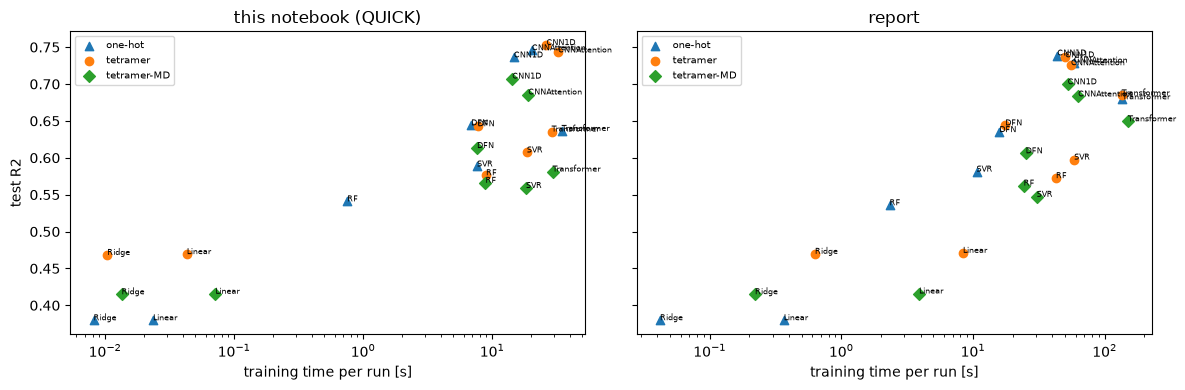

In [30]:
tcols = ['fs', 'model', 't_feat', 't_fit', 't_inf1k', 'test_r2']
T_ = BENCH[tcols].copy(); T_['model'] = T_.model.map(NM)
print(f'This notebook ({MODE}, {os.cpu_count()} CPU threads): training time per run [s]'); display(T_.pivot(index='model', columns='fs', values='t_fit').reindex(list(NM.values())).round(1))
print('inference [s per 1,000 sequences]'); display(T_.pivot(index='model', columns='fs', values='t_inf1k').reindex(list(NM.values())).round(3))
R_ = REPORT[REPORT.fs.isin(BENCH.fs.unique())][tcols].copy(); R_['model'] = R_.model.map(NM)
print('Report timing (training time per run [s])'); display(R_.pivot(index='model', columns='fs', values='t_fit').reindex(list(NM.values())).round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True); mk = dict(zip(FSN.values(), 'osv^Dpx'))
for a, df, t in [(ax[0], BENCH, f'this notebook ({MODE})'), (ax[1], REPORT[REPORT.fs.isin(BENCH.fs.unique())], 'report')]:
    for fs_, s in df.groupby('fs'):
        a.scatter(s.t_fit, s.test_r2, marker=mk[fs_], label=fs_)
        for _, r_ in s.iterrows(): a.annotate(NM[r_.model], (r_.t_fit, r_.test_r2), fontsize=6)
    a.set(xscale='log', xlabel='training time per run [s]', title=t); a.legend(fontsize=7)
ax[0].set_ylabel('test R2'); plt.tight_layout(); plt.show()

## Summary

* **MD alone predicts affinity well:** tetramer MD only (e) gives CNN1D a test R² of 0.700 in the report (one-hot only 0.739, MD + one-hot 0.736); hexamer MD alone is clearly worse (f).
* **The tables are tetramer lookups:** the 256 vectors identify the sequence; a shuffled table still gives CNN1D 0.68, but costs DFN 0.13 and RF 0.05 test R² (section 10).
* **LRP:** MD-only models rely mainly on the `fce` coupling terms (section 9).

Set `MODE = 'FULL'` (and `BENCH_SETS = 'abcdefg'`) to re-run the report's protocol; the exact report numbers are in `outputs/selex_new_shape/benchmark_featuresets.csv` and the PDF.